# Lecture 9 Activity – How does the United States compare in a 26-country road-deaths table?

QSS 20 · Modern Statistical Computing · Fall 2026

## The question

In lecture, US traffic deaths rose by 31 percent from 2013 to 2021, while New
York City's held level. A rise in one country can be part of a trend in many
countries, or a pattern of that country alone. Compare the United States
with the countries selected for the article's table.

Open [Wikipedia's Vision Zero page](https://en.wikipedia.org/wiki/Vision_Zero)
and find the table captioned "Road fatalities in 2013." Inspect its header
and one country row before running the starter code. Sweden's parliament
approved Vision Zero in 1997. The article compares 26 countries in 2013,
with deaths per million residents and per 100 billion vehicle-kilometers.
The first measure describes risk to residents; the second accounts for how
much people drive. The countries in this table are the comparison group.

> **Where does the United States rank among these 26 countries in 2013 on
> each measure?**

### How to work

Work in pairs for 35 minutes. Submit a 26-row country table, a checked US
comparison, a chart, and a short interpretation. Show the diagnostic output
that supports each claim. If you run out of time, finish Task 5 after class.

- This activity needs `beautifulsoup4`. If `import bs4` fails, run
  `conda activate qss20` and then `conda install beautifulsoup4` in a terminal.
- The row unit you build is **one country**.
- The page was saved on 2026-10-08 as `data/raw/wikipedia/vision-zero.html`.
  The live page may change. All code uses this saved copy and sends no requests.
- Print one complete row before you loop, and check your table against
  numbers the page reports.
- In the starter cells, replace each `...` with code.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from bs4 import BeautifulSoup

pd.set_option('display.max_rows', 30)

# Sharp figures on high-resolution screens, from lecture 6.
%config InlineBackend.figure_format = 'retina'

RAW = Path('../data/raw')
DERIVED = Path('../data/derived')   # tables saved in lecture 9
html = (RAW / 'wikipedia' / 'vision-zero.html').read_text(encoding='utf-8')
soup = BeautifulSoup(html, 'html.parser')

# Check: the page holds four tables of class wikitable.
len(soup.select('table.wikitable'))

4

## Task 1 · Find the right table

First run `soup.select_one('table.wikitable')` and print its caption: is it
the table you need? Then print the caption of every `wikitable` on the page,
and select the one whose caption contains `'Road fatalities in 2013'` as
`table`.

How many rows does `table` hold, and how many of them are countries?

In [2]:
first = soup.select_one('table.wikitable')
first.find('caption').get_text(' ', strip=True)

'Possible maximum travel speeds'

In [3]:
[t.find('caption').get_text(' ', strip=True)[:45]
 for t in soup.select('table.wikitable')]

['Possible maximum travel speeds',
 'Fatalities in Sweden',
 'Road fatalities in 2013, with comparison to 1',
 'Number of fatalities on Swedish roads [ 107 ]']

In [4]:
table = [t for t in soup.select('table.wikitable')
         if 'Road fatalities in 2013' in t.find('caption').get_text()][0]
len(table.find_all('tr'))

27

The first `wikitable` is "Possible maximum travel speeds", a table of speed
limits. Code built on it would run without an error and describe the wrong
thing. The country table is the third `wikitable`. It holds **27 rows**: one
header row and **26** countries.

## Task 2 · One row per country

Print the cells of the header row and of one country row. Then remove the
footnote marks and build a DataFrame `countries` with six columns: `country`,
`killed_1980`, `killed_2013`, `pct_of_1980`, `per_million`, and
`per_100bn_km`. Convert every column except `country` to numbers.

Which tag holds each country's name? Which column has missing values, and how
many? Explain why a missing distance rate must not become zero.

In [5]:
rows = table.find_all('tr')
print([c.get_text(' ', strip=True) for c in rows[0].find_all(['th', 'td'])])
print(rows[1].prettify())

['Country [ 104 ]', '1980 killed', '2013 killed', '2013/1980 percent', '2013 killed per million population', '2013 killed per 100 billion vehicle-kilometers']
<tr id="mwAs4">
 <th id="mwAs8" scope="row">
  Australia
 </th>
 <td id="mwAtA">
  3,272
 </td>
 <td id="mwAtE">
  1,185
 </td>
 <td id="mwAtI">
  36.2
 </td>
 <td id="mwAtM">
  51
 </td>
 <td id="mwAtQ">
  496
 </td>
</tr>



In [6]:
for s in table.select('sup.reference'):
    s.decompose()

columns = ['country', 'killed_1980', 'killed_2013', 'pct_of_1980',
           'per_million', 'per_100bn_km']
records = []
for row in rows[1:]:
    cells = [c.get_text(' ', strip=True) for c in row.find_all(['th', 'td'])]
    records.append(dict(zip(columns, cells)))
countries = pd.DataFrame(records)

for col in columns[1:]:
    countries[col] = pd.to_numeric(countries[col].str.replace(',', ''),
                                   errors='coerce')
countries.head(3)

,country,killed_1980,killed_2013,pct_of_1980,per_million,per_100bn_km
0,Australia,3272,1185,36.2,51,496.0
1,Austria,2003,455,22.7,54,583.0
2,Belgium,2396,723,30.2,65,707.0


In [7]:
len(countries), countries['country'].is_unique, countries.isna().sum()

(26,
 True,
 country          0
 killed_1980      0
 killed_2013      0
 pct_of_1980      0
 per_million      0
 per_100bn_km    10
 dtype: int64)

Each country's name sits in a **`th`** cell, a row header; only the numbers
are `td`. A loop over `row.find_all('td')` would drop every name and shift the
columns by one. `countries` has **26 rows**, one per country, with no name
repeated. Only `per_100bn_km` has missing values: **10** of the 26 countries
report no deaths per distance driven. Missing means the table gives no rate;
it does not mean zero deaths.

## Task 3 · Check the table against itself and against lecture

`pct_of_1980` should equal `killed_2013 / killed_1980 * 100`. Compute it
yourself and print the countries where your value and the page's value differ
by more than 0.5.

Then compare the US count for 2013 with the national table from lecture,
`data/derived/us_traffic_deaths.csv`. Do the two pages agree?

In [8]:
checked = countries.assign(
    own_pct=countries['killed_2013'] / countries['killed_1980'] * 100)
gap = (checked['own_pct'] - checked['pct_of_1980']).abs()
checked.loc[gap > 0.5, ['country', 'killed_1980', 'killed_2013',
                        'pct_of_1980', 'own_pct']].round(1)

,country,killed_1980,killed_2013,pct_of_1980,own_pct
4,Czech Republic,1261,655,52.9,51.9
18,Portugal,2850,637,23.4,22.4


In [9]:
us_year = pd.read_csv(DERIVED / 'us_traffic_deaths.csv')
(countries.loc[countries['country'] == 'United States', 'killed_2013'].item(),
 us_year.loc[us_year['year'] == 2013, 'deaths'].item())

(32719, 32893)

The page's percentages agree with the counts to within 0.5 for every country
but two. For the Czech Republic and Portugal, the page's percentage is 1.0
higher than its own counts give. One of the numbers in each of those rows is
wrong, and the table alone cannot say which; the cited source can. Compute
rates from the counts, and check doubtful rows against the source.

The two Wikipedia pages disagree about the United States in 2013: **32,719**
here and **32,893** in the national table, 174 deaths apart. Each page cites a
different compilation. The gap is half a percent, too small to change the
ranking below, but a paper should cite one source and say which.

## Task 4 · ❓ Where does the United States rank?

Draw `per_million` for all 26 countries as a horizontal bar chart, sorted,
with the United States in a different color. Then report the US rank on three
measures: `per_million`, `pct_of_1980` (higher means deaths fell less), and
`per_100bn_km` (among the countries that report it).

Is the United States an outlier on every measure?

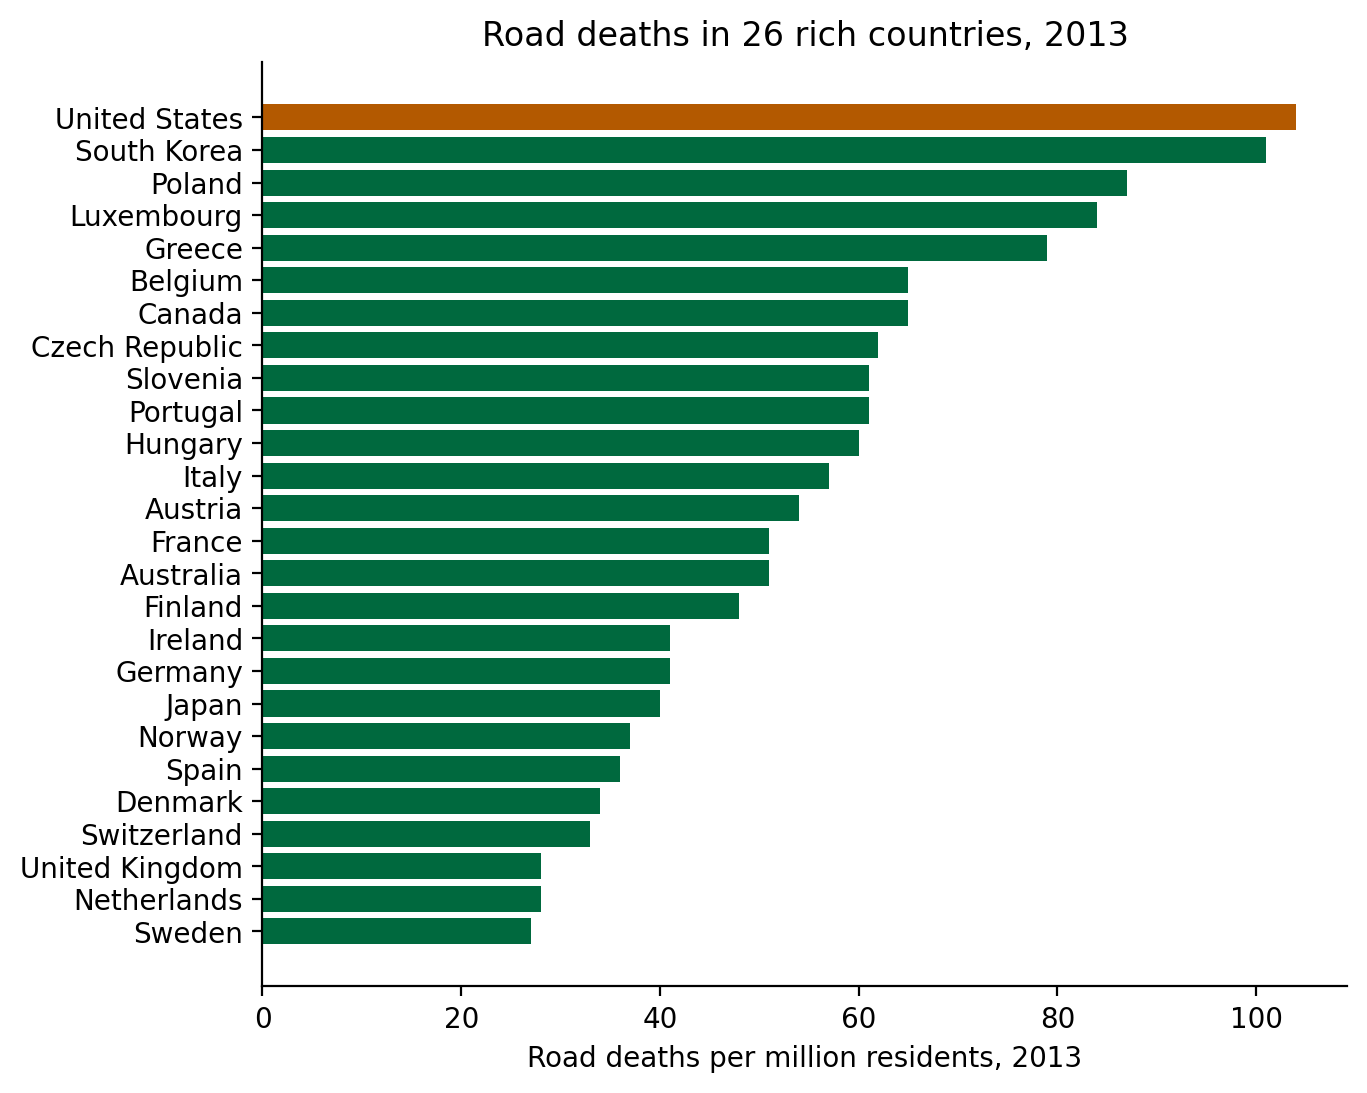

In [10]:
ordered = countries.sort_values('per_million')
colors = ['#b35900' if c == 'United States' else '#00693e'
          for c in ordered['country']]

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(ordered['country'], ordered['per_million'], color=colors)
ax.set(xlabel='Road deaths per million residents, 2013',
       title='Road deaths in 26 rich countries, 2013')
ax.spines[['top', 'right']].set_visible(False);

In [11]:
ranks = countries.assign(
    rank_per_million=countries['per_million'].rank(ascending=False),
    rank_pct_of_1980=countries['pct_of_1980'].rank(ascending=False),
    rank_per_km=countries['per_100bn_km'].rank(ascending=False))
ranks.loc[ranks['country'] == 'United States',
          ['per_million', 'rank_per_million', 'pct_of_1980',
           'rank_pct_of_1980', 'per_100bn_km', 'rank_per_km']]

,per_million,rank_per_million,pct_of_1980,rank_pct_of_1980,per_100bn_km,rank_per_km
25,104,1.0,64.0,2.0,680.0,5.0


Per resident, the United States is **first of 26**: 104 deaths per million,
above South Korea (101) and about twice the median country (52.5). Sweden,
the United Kingdom, and the Netherlands had 27 or 28.

Since 1980, US deaths fell to **64 percent** of their 1980 level, the second
smallest decline; only South Korea's (79 percent) was smaller. Most countries
cut their deaths to between 22 and 56 percent.

Per distance driven, the United States ranks **5th of the 16** countries that
report it: 680 deaths per 100 billion vehicle-kilometers, about twice Sweden's
337, and below South Korea, the Czech Republic, Belgium, and Japan. The US
rate per resident is 3.9 times Sweden's, but per kilometer only 2.0 times: in
these figures, each American drives about twice as far as each Swede.

## Task 5 · What the table cannot tell you

Write three or four sentences. What does it mean that the US ranks first per
resident but fifth per distance driven? Name two limits of this table as
evidence about road safety policy.

Per resident, the United States has the most road deaths among these 26
countries. Per kilometer driven, it ranks 5th of the 16 that report that
measure. Much of the gap comes from how far Americans drive, and the rest
from how dangerous each kilometer is. Each measure answers a different
question: the risk to a resident, or the risk per kilometer driven.

The table has two limits. It describes one year, 2013, so it shows levels and
not the trends that a policy would change. And its source chose the 26
countries, with distance data missing for 10 of them, so the ranking per
distance covers only 16 countries.

## What to take from this

- Choose a table by its caption or class and print it before you parse; the
  first table on a page is often a different one.
- Row headers are `th` cells. Search for `['th', 'td']` when you need every
  cell.
- A count per resident and a count per kilometer answer different questions.
  Say which one supports your claim.